# OpenCode with the AWS CLI against IaCGen-MAS, OpenCode with the Validator, IaCGen and zero-shot

## Setup

In [1]:
import sys, os, re, json, csv, glob, warnings, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
csv.field_size_limit(sys.maxsize)

FINAL = Path("../results"); DATA = Path("../data"); RES = Path("result/final")
RUNS = Path(os.environ.get("IACGOD_RUNS", "../runs"))
CACHE = FINAL / "_analysis_cache"; CACHE.mkdir(exist_ok=True)
FIG = Path("plots/opencode_agent"); FIG.mkdir(parents=True, exist_ok=True)
OUT = RES
plt.style.use("ggplot"); sns.set_palette("muted")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 90)

AGENT = "CFN_RealAWS_OpencodeAgent_DSV4F"
SYSTEMS = {
    "IaCGen-MAS": "CFN_RealAWS_DSV4F",
    "OpenCode + Validator": "CFN_RealAWS_OpenCode_DSV4F",
    "OpenCode (AWS CLI)": AGENT,
    "IaCGen": "CFN_RealAWS_IaCGen_DSV4Flash",
    "Zero-shot": "CFN_RealAWS_OneShot_DSV4F",
}
ORDER = list(SYSTEMS)
PALETTE = dict(zip(ORDER, sns.color_palette("muted", len(ORDER))))
PRICE = (0.0121, 1.28)

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

def holm(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def mcnemar_exact(a, b):
    only_a = int((a & ~b).sum()); only_b = int((~a & b).sum())
    n = only_a + only_b
    p = 1.0 if n == 0 else stats.binomtest(min(only_a, only_b), n, 0.5).pvalue
    return dict(both=int((a & b).sum()), only_first=only_a, only_second=only_b, neither=int((~a & ~b).sum()), p=p)

## Load the results

In [2]:
bench = pd.read_csv(DATA / "cfn_eval_benchmark_real_aws.csv").drop_duplicates("row_number").set_index("row_number")
dcol = "difficulty" if "difficulty" in bench else "difficulty_level"

def trivy_table(e):
    t = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python").drop_duplicates("run_id")
    t["severe"] = (t.severity_critical_failed.fillna(0) + t.severity_high_failed.fillna(0)) > 0
    return t

frames = []
for name, e in SYSTEMS.items():
    r = pd.read_csv(FINAL / e / "results_final.csv", engine="python")
    r["system"] = name; r["exp"] = e
    r["difficulty"] = r.row_number.map(bench[dcol])
    r["passed"] = r.final_validation_passed.astype(str).str.lower().eq("true")
    if name == "OpenCode + Validator":
        r["passed"] = r.passed & (r.iterations_used <= 15)
    if name == "IaCGen":
        r["deploys"] = r.passed
        r = r.merge(trivy_table(e)[["run_id", "severe"]], on="run_id", how="left")
        r["passed"] = r.deploys & r.severe.eq(False)
    frames.append(r)
runs = pd.concat(frames, ignore_index=True)
runs["system"] = pd.Categorical(runs.system, ORDER, ordered=True)
agent = runs[runs.system == "OpenCode (AWS CLI)"].copy()
runs.groupby("system", observed=True).agg(rows=("row_number", "size"), passed=("passed", "sum"))

,rows,passed
system,,
IaCGen-MAS,250,247
OpenCode + Validator,250,227
OpenCode (AWS CLI),250,214
IaCGen,250,181
Zero-shot,250,97


## Pass rate

In [3]:
rows = []
for name, g in runs.groupby("system", observed=True, sort=False):
    lo, hi = wilson(int(g.passed.sum()), len(g))
    rows.append(dict(system=name, rows=len(g), passed=int(g.passed.sum()), pass_rate=g.passed.mean(), ci_lo=lo, ci_hi=hi))
iacgen_dep = runs[runs.system == "IaCGen"]
lo, hi = wilson(int(iacgen_dep.deploys.sum()), len(iacgen_dep))
rows.append(dict(system="IaCGen, deploys only", rows=len(iacgen_dep), passed=int(iacgen_dep.deploys.sum()), pass_rate=iacgen_dep.deploys.mean(), ci_lo=lo, ci_hi=hi))
HEAD = pd.DataFrame(rows)
HEAD.round(4)

,system,rows,passed,pass_rate,ci_lo,ci_hi
0,IaCGen-MAS,250,247,0.988,0.9653,0.9959
1,OpenCode + Validator,250,227,0.908,0.8657,0.9379
2,OpenCode (AWS CLI),250,214,0.856,0.8071,0.8941
3,IaCGen,250,181,0.724,0.6655,0.7757
4,Zero-shot,250,97,0.388,0.3297,0.4497
5,"IaCGen, deploys only",250,219,0.876,0.8294,0.9113


## Pass rate by difficulty level

difficulty,1,2,3,4,5
system,,,,,
IaCGen-MAS,96.0,100.0,100.0,100.0,98.0
OpenCode + Validator,96.0,94.0,98.0,80.0,86.0
OpenCode (AWS CLI),92.0,92.0,82.0,84.0,78.0
IaCGen,76.0,88.0,72.0,60.0,66.0
Zero-shot,54.0,56.0,36.0,22.0,26.0


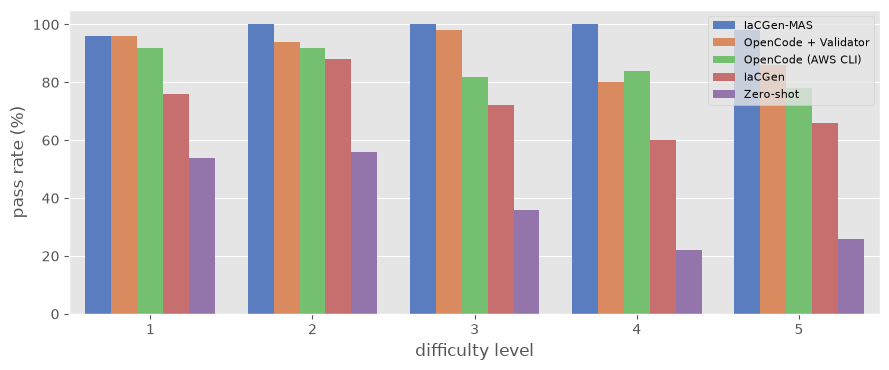

In [4]:
LEVEL = runs.pivot_table(index="system", columns="difficulty", values="passed", aggfunc="mean", observed=True).mul(100).round(1)
display(LEVEL)
fig, ax = plt.subplots(figsize=(9, 3.8))
d = runs.groupby(["difficulty", "system"], observed=True).passed.mean().mul(100).reset_index()
sns.barplot(data=d, x="difficulty", y="passed", hue="system", hue_order=ORDER, palette=PALETTE, ax=ax)
ax.set_xlabel("difficulty level"); ax.set_ylabel("pass rate (%)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "pass_by_level.png", dpi=160); plt.show()

## Paired comparisons with the coding agent

In [5]:
ag = agent.set_index("row_number")
pairs = []
for name in ORDER:
    if name == "OpenCode (AWS CLI)":
        continue
    o = runs[runs.system == name].set_index("row_number")
    idx = ag.index.intersection(o.index)
    for crit, col in (("deployable and secure", "passed"), ("deploys", "deploys")):
        if col not in o or o[col].isna().all():
            continue
        m = mcnemar_exact(ag.loc[idx].passed.values, o.loc[idx, col].astype(bool).values)
        pairs.append(dict(other=name, other_criterion=crit, rows=len(idx), agent_pass=int(ag.loc[idx].passed.sum()),
                          other_pass=int(o.loc[idx, col].astype(bool).sum()), only_agent=m["only_first"], only_other=m["only_second"], p=m["p"]))
PAIRS = pd.DataFrame(pairs)
PAIRS["p_holm"] = holm(PAIRS.p.values)
PAIRS.round(4)

,other,other_criterion,rows,agent_pass,other_pass,only_agent,only_other,p,p_holm
0,IaCGen-MAS,deployable and secure,250,214,247,1,34,0.0000,0.0000
1,OpenCode + Validator,deployable and secure,250,214,227,15,28,0.0660,0.1320
2,IaCGen,deployable and secure,250,214,181,54,21,0.0002,0.0005
3,IaCGen,deploys,250,214,219,23,28,0.5758,0.5758
4,Zero-shot,deployable and secure,250,214,97,122,5,0.0000,0.0000


## Effort and cost

In [6]:
def eff(g):
    c = g.token_input_tokens.fillna(0) / 1e6 * PRICE[0] + g.token_output_tokens.fillna(0) / 1e6 * PRICE[1]
    return pd.Series(dict(rows=len(g), llm_calls_mean=g.llm_calls_total.mean(), llm_calls_median=g.llm_calls_total.median(),
                          tokens_k_mean=g.token_all_tokens.mean() / 1e3, input_k_mean=g.token_input_tokens.mean() / 1e3,
                          output_k_mean=g.token_output_tokens.mean() / 1e3, minutes_mean=g.duration_seconds.mean() / 60,
                          minutes_median=g.duration_seconds.median() / 60, usd_per_scenario=c.mean(),
                          shell_calls_mean=g.agent_shell_calls.mean(), aws_calls_mean=g.agent_aws_calls.mean(),
                          deploy_attempts_mean=g.agent_deploy_attempts.mean(), deploy_attempts_median=g.agent_deploy_attempts.median()))
AGENT_EFFORT = pd.concat({"all": eff(agent), "passed": eff(agent[agent.passed]), "failed": eff(agent[~agent.passed])}, axis=1).T.round(3)
display(AGENT_EFFORT)
J = pd.read_csv(FINAL / "repair_loop_tables" / "J_llm_cost.csv")
J = J[J.run.isin(SYSTEMS.values())][["run", "approach", "pass_pct", "llm_calls_mean", "prompt_ktok_mean", "completion_ktok_mean", "usd_per_scenario", "usd_per_pass"]]
a = AGENT_EFFORT.loc["all"]
J = pd.concat([J, pd.DataFrame([dict(run=AGENT, approach="OpenCode (AWS CLI)", pass_pct=100 * agent.passed.mean(), llm_calls_mean=a.llm_calls_mean,
                                     prompt_ktok_mean=a.input_k_mean, completion_ktok_mean=a.output_k_mean, usd_per_scenario=a.usd_per_scenario,
                                     usd_per_pass=a.usd_per_scenario * len(agent) / agent.passed.sum())])], ignore_index=True)
other = runs[runs.system.isin(["IaCGen-MAS", "OpenCode + Validator"])].groupby("system", observed=True).agg(minutes_mean=("duration_seconds", lambda s: s.mean() / 60), tokens_k_mean=("token_all_tokens", lambda s: s.mean() / 1e3))
display(other.round(2))
COST = J.round(4)
COST

,rows,llm_calls_mean,llm_calls_median,tokens_k_mean,input_k_mean,output_k_mean,minutes_mean,minutes_median,usd_per_scenario,shell_calls_mean,aws_calls_mean,deploy_attempts_mean,deploy_attempts_median
all,250.0,50.908,32.5,190.541,176.939,13.602,21.351,10.662,0.020,44.952,26.496,4.292,2.0
passed,214.0,45.187,27.5,173.876,161.821,12.055,18.710,9.698,0.017,40.187,22.855,3.799,2.0
failed,36.0,84.917,60.0,289.606,266.809,22.798,37.053,19.134,0.032,73.278,48.139,7.222,4.5


,minutes_mean,tokens_k_mean
system,,
IaCGen-MAS,21.18,151.11
OpenCode + Validator,14.52,41.65


,run,approach,pass_pct,llm_calls_mean,prompt_ktok_mean,completion_ktok_mean,usd_per_scenario,usd_per_pass
0,CFN_RealAWS_DSV4F,IaCGen-MAS,98.8,10.100,124.900,26.200,0.0350,0.0354
1,CFN_RealAWS_OneShot_DSV4F,Zero-shot,38.8,1.000,0.600,14.600,0.0187,0.0482
2,CFN_RealAWS_OpenCode_DSV4F,OpenCode+Validator,90.8,13.500,34.100,13.700,0.0180,0.0198
3,CFN_RealAWS_OpencodeAgent_DSV4F,OpenCode (AWS CLI),85.6,50.908,176.939,13.602,0.0200,0.0234


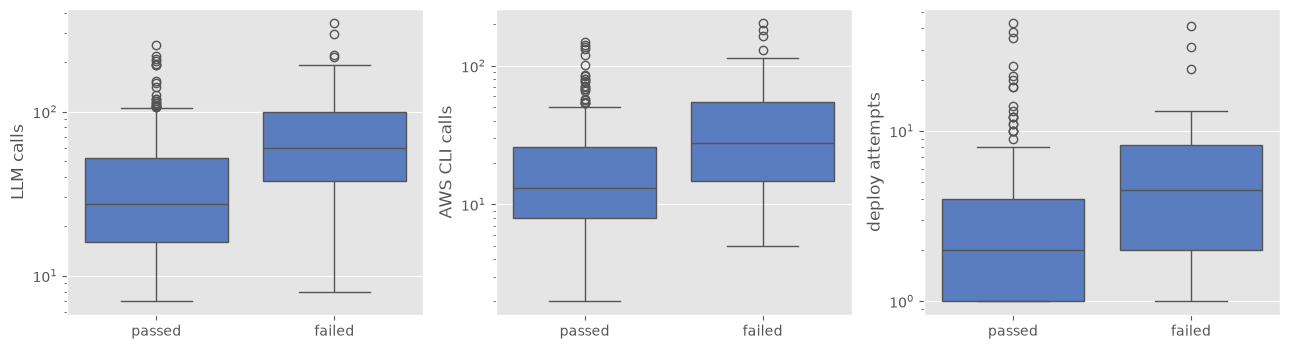

llm_calls_total          0.00007
token_all_tokens         0.00001
agent_aws_calls          0.00004
agent_deploy_attempts    0.00002
duration_seconds         0.00078
Name: mann_whitney_p, dtype: float64

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, lab in zip(axes, ["llm_calls_total", "agent_aws_calls", "agent_deploy_attempts"], ["LLM calls", "AWS CLI calls", "deploy attempts"]):
    sns.boxplot(data=agent.assign(outcome=np.where(agent.passed, "passed", "failed")), x="outcome", y=col, ax=ax, order=["passed", "failed"])
    ax.set_ylabel(lab); ax.set_xlabel(""); ax.set_yscale("log")
plt.tight_layout(); plt.savefig(FIG / "agent_effort_by_outcome.png", dpi=160); plt.show()
w = {c: stats.mannwhitneyu(agent.loc[agent.passed, c], agent.loc[~agent.passed, c]).pvalue for c in ["llm_calls_total", "token_all_tokens", "agent_aws_calls", "agent_deploy_attempts", "duration_seconds"]}
pd.Series(w, name="mann_whitney_p").round(5)

## Why the coding agent fails

In [8]:
def stage_failed(r):
    for s in ("yaml", "cfn-lint", "trivy"):
        v = r.get(f"val_stage_{s}_passed")
        if pd.notna(v) and str(v).lower() == "false":
            return s
    return None

def category(r):
    msg = f"{r.get('deploy_error_message') or ''} {r.get('invalid_reason') or ''}"
    if r.status == "workspace_escape":
        return "workspace escape"
    if r.status == "harness_timeout":
        return "session timeout"
    s = stage_failed(r)
    if s:
        return {"yaml": "syntax", "cfn-lint": "schema", "trivy": "security"}[s]
    if "Required parameter has no Default" in msg:
        return "parameter without default"
    if "InsufficientCapabilities" in msg or "CAPABILITY_AUTO_EXPAND" in msg:
        return "capability not granted"
    if "created 0 resources" in msg:
        return "no resources created"
    if "already exists" in msg:
        return "name already in use"
    if "Stalled in CREATE_IN_PROGRESS" in msg or "stalled in CREATE_IN_PROGRESS" in msg:
        return "stalled deployment"
    if re.search(r"can't create new App Runner|not subscribed|Index type could not be updated|InternalFailure", msg):
        return "account or service restriction"
    return "other deployment error"

GROUP = {"parameter without default": "scoring rule the agent's test skipped", "capability not granted": "scoring rule the agent's test skipped",
         "no resources created": "scoring rule the agent's test skipped", "syntax": "static check", "schema": "static check", "security": "static check",
         "workspace escape": "harness", "session timeout": "harness", "name already in use": "deployment environment",
         "stalled deployment": "deployment environment", "account or service restriction": "deployment environment", "other deployment error": "deployment error"}
fails = agent[~agent.passed].copy()
fails["category"] = fails.apply(category, axis=1)
fails["group"] = fails.category.map(GROUP)
FAIL_CAT = fails.groupby(["group", "category"]).agg(rows=("row_number", "size"), row_numbers=("row_number", lambda s: ", ".join(map(str, sorted(s))))).reset_index()
FAIL_CAT

,group,category,rows,row_numbers
0,deployment environment,account or service restriction,2,"34, 244"
1,deployment environment,name already in use,7,"13, 56, 80, 114, 161, 183, 254"
2,deployment environment,stalled deployment,2,"6, 77"
3,deployment error,other deployment error,2,"133, 230"
4,harness,session timeout,3,"152, 159, 174"
5,harness,workspace escape,6,"50, 69, 89, 93, 143, 181"
6,scoring rule the agent's test skipped,capability not granted,1,202
7,scoring rule the agent's test skipped,no resources created,3,"97, 104, 217"
8,scoring rule the agent's test skipped,parameter without default,5,"150, 203, 220, 251, 252"
9,static check,schema,1,206


## The agent's own tests

In [9]:
PAT = {
    "deploy_cmd": re.compile(r"aws\s+cloudformation\s+(deploy|create-stack|update-stack)"),
    "param_overrides": re.compile(r"--parameter-overrides|--parameters\s"),
    "auto_expand": re.compile(r"CAPABILITY_AUTO_EXPAND"),
    "cfn_lint": re.compile(r"\bcfn-lint\b"),
    "yamllint": re.compile(r"\byamllint\b"),
    "trivy": re.compile(r"\btrivy\b"),
    "delete_stack": re.compile(r"delete-stack"),
    "web_request": re.compile(r"(curl|wget|urllib|requests\.get|http\.client)[^\n]*https?://"),
}
COMPLETE = re.compile(r"\b(CREATE_COMPLETE|UPDATE_COMPLETE)\b|Successfully created/updated stack")

def find_run(rid):
    for p in (RUNS / rid, *RUNS.glob(f"*/{rid}")):
        if (p / "harness_stream.jsonl").exists():
            return p
    return None

def session_features(rid):
    p = find_run(rid)
    rec = dict(run_id=rid, found=p is not None, bash_calls=0, saw_complete=False, **{k: 0 for k in PAT})
    if p is None:
        return rec
    for line in open(p / "harness_stream.jsonl", errors="ignore"):
        try:
            e = json.loads(line)
        except Exception:
            continue
        if e.get("type") != "tool_use" or e.get("part", {}).get("tool") != "bash":
            continue
        st = e["part"].get("state", {})
        cmd = str(st.get("input", {}).get("command", ""))
        out = str(st.get("output", "")) + str((st.get("metadata") or {}).get("output", ""))
        rec["bash_calls"] += 1
        for k, rx in PAT.items():
            if rx.search(cmd):
                rec[k] += 1
        if COMPLETE.search(out):
            rec["saw_complete"] = True
    return rec

cache = CACHE / f"agent_sessions_{AGENT}.csv"
rids = sorted(agent.run_id.dropna().astype(str))
if cache.exists() and sorted(pd.read_csv(cache).run_id.astype(str)) == rids:
    SESS = pd.read_csv(cache)
else:
    if not RUNS.exists():
        raise FileNotFoundError(f"{RUNS} is missing and no cache for {AGENT}; set IACGOD_RUNS")
    SESS = pd.DataFrame([session_features(r) for r in rids])
    SESS.to_csv(cache, index=False)
SESS["run_id"] = SESS.run_id.astype(str)
S = agent.assign(run_id=agent.run_id.astype(str)).merge(SESS, on="run_id", how="left")
S = S.merge(fails[["row_number", "category", "group"]], on="row_number", how="left")
S["outcome"] = np.where(S.passed, "passed", "failed")
SELFTEST = S.groupby("outcome").agg(rows=("row_number", "size"), ran_a_deploy=("deploy_cmd", lambda s: int((s > 0).sum())),
                                    saw_create_complete=("saw_complete", "sum"), used_parameter_values=("param_overrides", lambda s: int((s > 0).sum())),
                                    used_auto_expand=("auto_expand", lambda s: int((s > 0).sum())), ran_cfn_lint=("cfn_lint", lambda s: int((s > 0).sum())),
                                    ran_trivy=("trivy", lambda s: int((s > 0).sum())), deleted_a_stack=("delete_stack", lambda s: int((s > 0).sum())),
                                    web_requests=("web_request", lambda s: int((s > 0).sum())))
display(SELFTEST)
S[~S.passed].groupby("category").agg(rows=("row_number", "size"), saw_create_complete=("saw_complete", "sum"),
                                       used_parameter_values=("param_overrides", lambda s: int((s > 0).sum())), deleted_a_stack=("delete_stack", lambda s: int((s > 0).sum())))

,rows,ran_a_deploy,saw_create_complete,used_parameter_values,used_auto_expand,ran_cfn_lint,ran_trivy,deleted_a_stack,web_requests
outcome,,,,,,,,,
failed,36,36,31,12,4,36,35,36,5
passed,214,214,184,34,15,214,213,214,14


,rows,saw_create_complete,used_parameter_values,deleted_a_stack
category,,,,
account or service restriction,2,2,0,2
capability not granted,1,1,1,1
name already in use,7,4,1,7
no resources created,3,3,2,3
other deployment error,2,2,1,2
parameter without default,5,5,5,5
schema,1,1,0,1
security,3,3,1,3
session timeout,3,1,0,3


In [10]:
FALSE_OK = S[~S.passed & S.saw_complete & ~S.category.isin(["workspace escape", "session timeout"])]
print(f"failed rows where the agent saw its own stack complete: {len(FALSE_OK)} of {int((~S.passed).sum())}")
print(f"passed rows where the agent never saw a stack complete: {int((S.passed & ~S.saw_complete).sum())} of {int(S.passed.sum())}")
FALSE_OK.category.value_counts()

failed rows where the agent saw its own stack complete: 24 of 36
passed rows where the agent never saw a stack complete: 30 of 214


category
parameter without default         5
name already in use               4
no resources created              3
security                          3
stalled deployment                2
account or service restriction    2
other deployment error            2
syntax                            1
capability not granted            1
schema                            1
Name: count, dtype: int64

## Security audit of the final templates

In [11]:
sv = []
for name, e in SYSTEMS.items():
    t = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python").drop_duplicates("run_id")
    t = t[t.run_id.isin(runs.loc[runs.exp == e, "run_id"].dropna()) & t.total_checks.notna()]
    rec = dict(system=name, templates=len(t), policy_pass_pct=100 * (t.total_passed / t.total_checks).mean(), clean_pct=100 * t.trivy_passed.astype(bool).mean(),
               with_critical_or_high_pct=100 * ((t.severity_critical_failed.fillna(0) + t.severity_high_failed.fillna(0)) > 0).mean())
    for sev in ("critical", "high", "medium", "low"):
        rec[f"{sev}_pass_pct"] = 100 * t[f"severity_{sev}_passed"].sum() / t[f"severity_{sev}_eval"].sum()
    sv.append(rec)
SEC = pd.DataFrame(sv).round(2)
SEC

,system,templates,policy_pass_pct,clean_pct,with_critical_or_high_pct,critical_pass_pct,high_pass_pct,medium_pass_pct,low_pass_pct
0,IaCGen-MAS,250,95.40,40.8,0.8,100.00,99.91,95.79,81.89
1,OpenCode + Validator,250,96.25,44.8,1.2,100.00,99.68,96.72,85.51
2,OpenCode (AWS CLI),250,96.00,43.6,2.4,100.00,98.90,96.83,84.38
3,IaCGen,250,94.66,41.2,18.8,96.88,94.33,96.88,82.68
4,Zero-shot,250,95.84,49.2,16.4,97.44,95.90,97.37,86.84


## Resource coverage of the final templates

In [12]:
cv = []
for name, e in SYSTEMS.items():
    c = pd.read_csv(RES / f"Coverage_{e}.csv", engine="python")
    c = c[c.row_number.isin(runs.loc[(runs.exp == e) & runs.run_id.notna(), "row_number"])].drop_duplicates("row_number")
    cv.append(dict(system=name, templates=len(c), recall_pct=c.coverage_pct.mean(), precision_pct=c.accuracy_pct.mean(),
                   extra_mean=c.extra_resources.mean(), missing_mean=c.missing_resources.mean()))
COVERAGE = pd.DataFrame(cv).round(2)
COVERAGE

,system,templates,recall_pct,precision_pct,extra_mean,missing_mean
0,IaCGen-MAS,250,86.02,81.34,2.42,1.42
1,OpenCode + Validator,250,86.34,84.69,2.13,1.46
2,OpenCode (AWS CLI),250,88.11,84.22,2.22,1.38
3,IaCGen,250,85.38,87.12,1.74,1.54
4,Zero-shot,250,83.11,84.65,1.48,1.82


## Summary tables

In [13]:
HEAD.round(4).to_csv(OUT / "OpencodeAgent_pass.csv", index=False)
LEVEL.reset_index().to_csv(OUT / "OpencodeAgent_pass_by_level.csv", index=False)
PAIRS.round(4).to_csv(OUT / "OpencodeAgent_paired.csv", index=False)
AGENT_EFFORT.reset_index(names="rows_of").to_csv(OUT / "OpencodeAgent_effort.csv", index=False)
COST.to_csv(OUT / "OpencodeAgent_cost.csv", index=False)
FAIL_CAT.to_csv(OUT / "OpencodeAgent_failures.csv", index=False)
SELFTEST.reset_index().to_csv(OUT / "OpencodeAgent_selftest.csv", index=False)
SEC.to_csv(OUT / "OpencodeAgent_security.csv", index=False)
COVERAGE.to_csv(OUT / "OpencodeAgent_resources.csv", index=False)
HEAD.round(4)

,system,rows,passed,pass_rate,ci_lo,ci_hi
0,IaCGen-MAS,250,247,0.988,0.9653,0.9959
1,OpenCode + Validator,250,227,0.908,0.8657,0.9379
2,OpenCode (AWS CLI),250,214,0.856,0.8071,0.8941
3,IaCGen,250,181,0.724,0.6655,0.7757
4,Zero-shot,250,97,0.388,0.3297,0.4497
5,"IaCGen, deploys only",250,219,0.876,0.8294,0.9113
